In [1]:
# ---------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ---------------------------------------------------------------

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection: hyperparameter tuning, data splitting and cross-validation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Metrics used to evaluate classification performance
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# Logistic Regression classifier (our base model)
from sklearn.linear_model import LogisticRegression

# Statistical tests (used for the Chi-square test)
import scipy.stats as stats

# Techniques to handle class imbalance
from imblearn.over_sampling import SMOTE              # Synthetic oversampling of the minority class
from imblearn.under_sampling import RandomUnderSampler  # Random removal of majority-class rows

# Suppress warning messages to keep the notebook output clean
import warnings

warnings.filterwarnings("ignore")

**Observations:**

- All the libraries needed for data handling, plotting, modelling, statistical testing and class-imbalance handling are loaded.
- Warnings are suppressed so the notebook output stays clean.

In [2]:
# ---------------------------------------------------------------
# 2. LOAD THE DATASET
# ---------------------------------------------------------------

# Read the loan delinquency CSV file into a DataFrame
# (r"..." is a raw string, so the backslashes in the Windows path are read literally)
data = pd.read_csv(r"C:\Users\DELL\Downloads\Loan_Delinquent_Dataset (1).csv")

**Observations:**

- The loan delinquency dataset is loaded from a local CSV file into a DataFrame.
- The path is specific to the user's machine, so it needs to be changed when the notebook is run elsewhere.

In [3]:
# Check the size of the dataset -> (number of rows, number of columns)
data.shape

(11548, 8)

**Observations:**

- The dataset has **11,548 rows and 8 columns**.
- This is a reasonably large sample for a logistic regression model with a handful of categorical predictors.

In [4]:
# Work on a copy so the original data stays untouched
loan = data.copy()

**Observations:**

- A copy (`loan`) is created, so the raw `data` stays available if anything needs to be re-checked.

In [5]:
# View the first 5 rows to understand the structure of the data
loan.head()

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
0,1,1,36 months,Female,House,Mortgage,>25,300-500
1,2,0,36 months,Female,House,Rent,20-25,>500
2,3,1,36 months,Female,House,Rent,>25,300-500
3,4,1,36 months,Female,Car,Mortgage,>25,300-500
4,5,1,36 months,Female,House,Rent,>25,300-500


**Observations:**

- Columns are `ID`, `isDelinquent` (target), `term`, `gender`, `purpose`, `home_ownership`, `age` and `FICO`.
- All predictors are categorical: `age` and `FICO` are already grouped into bands (20-25 / >25 and 300-500 / >500).
- `isDelinquent` is coded 1 (delinquent) and 0 (not delinquent).

In [6]:
# View the last 5 rows to confirm the data was loaded completely
loan.tail()

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
11543,11544,0,60 months,Male,other,Mortgage,>25,300-500
11544,11545,1,36 months,Male,House,Rent,20-25,300-500
11545,11546,0,36 months,Female,Personal,Mortgage,20-25,>500
11546,11547,1,36 months,Female,House,Rent,20-25,300-500
11547,11548,1,36 months,Male,Personal,Mortgage,20-25,300-500


**Observations:**

- The last row has ID 11548, so the whole file was loaded without truncation.
- The purpose value `other` appears in lowercase here, which hints at a labelling inconsistency (fixed later).

In [7]:
# Check column names, data types and non-null counts
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ID              11548 non-null  int64 
 1   isDelinquent    11548 non-null  int64 
 2   term            11548 non-null  object
 3   gender          11548 non-null  object
 4   purpose         11548 non-null  object
 5   home_ownership  11548 non-null  object
 6   age             11548 non-null  object
 7   FICO            11548 non-null  object
dtypes: int64(2), object(6)
memory usage: 721.9+ KB


**Observations:**

- There are **no missing values**: all 8 columns have 11,548 non-null entries.
- 6 columns are stored as `object` and 2 as `int64`. The text columns should be converted to `category`.

In [8]:
# ---------------------------------------------------------------
# 3. DATA PREPROCESSING
# ---------------------------------------------------------------

# Convert all columns to the 'category' data type, because each of them
# holds a limited set of labels (e.g. Male/Female) rather than continuous numbers.
# This also reduces memory usage.
loan["term"] = loan["term"].astype("category")
loan["gender"] = loan["gender"].astype("category")
loan["purpose"] = loan["purpose"].astype("category")
loan["home_ownership"] = loan["home_ownership"].astype("category")
loan["age"] = loan["age"].astype("category")
loan["FICO"] = loan["FICO"].astype("category")
loan["isDelinquent"] = loan["isDelinquent"].astype("category")  # Target variable (1 = delinquent, 0 = not delinquent)

**Observations:**

- All seven modelling columns are converted to the `category` type, since they hold a limited set of labels.
- The target `isDelinquent` is also treated as a category (1 = delinquent, 0 = not delinquent).

In [9]:
# Re-check data types to confirm the conversion to category worked
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11548 entries, 0 to 11547
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   ID              11548 non-null  int64   
 1   isDelinquent    11548 non-null  category
 2   term            11548 non-null  category
 3   gender          11548 non-null  category
 4   purpose         11548 non-null  category
 5   home_ownership  11548 non-null  category
 6   age             11548 non-null  category
 7   FICO            11548 non-null  category
dtypes: category(7), int64(1)
memory usage: 170.4 KB


**Observations:**

- After conversion, 7 columns are `category` and only `ID` remains `int64`.
- Memory usage dropped from about 722 KB to about 170 KB (roughly 76% lower).

In [10]:
# Count fully duplicated rows (0 means there are no duplicates)
loan.duplicated().sum()

np.int64(0)

**Observations:**

- There are **0 duplicated rows**, so no de-duplication is needed.

In [11]:
# Count missing values in each column
loan.isnull().sum()

ID                0
isDelinquent      0
term              0
gender            0
purpose           0
home_ownership    0
age               0
FICO              0
dtype: int64

**Observations:**

- There are **no missing values in any column**, so no imputation is required.

In [12]:
# Statistical summary of all columns
# (count, unique values, most frequent value and its frequency for categorical data)
loan.describe(include="all")

,ID,isDelinquent,term,gender,purpose,home_ownership,age,FICO
count,11548.000000,11548.0,11548,11548,11548,11548,11548,11548
unique,NaN,2.0,2,2,7,3,2,2
top,NaN,1.0,36 months,Male,House,Mortgage,20-25,300-500
freq,NaN,7721.0,10589,6555,6892,5461,5888,6370
mean,5774.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3333.764789,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2887.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,5774.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,8661.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations:**

- `isDelinquent`: 7,721 of 11,548 loans are delinquent. The target is imbalanced.
- `term`: 36 months is by far the most common (10,589 rows).
- `gender`: Male is the top category (6,555). `purpose`: House is the top category (6,892).
- `home_ownership`: Mortgage is the top category (5,461). `age`: 20-25 is the top group (5,888). `FICO`: 300-500 is the top band (6,370).
- `purpose` shows 7 unique values, which includes the duplicate `other` / `Other` label.

In [13]:
# Check if every ID is unique (it should equal the number of rows)
loan["ID"].nunique()

11548

**Observations:**

- All **11,548 IDs are unique**, equal to the number of rows.
- `ID` is just an identifier with no predictive value, so it can be dropped.

In [14]:
# ID is only an identifier and has no predictive value, so drop it
loan.drop(["ID"], axis=1, inplace=True)

**Observations:**

- `ID` is removed, leaving 7 columns: the target plus 6 predictors.

In [15]:
# Look at the distinct categories in 'purpose' to spot inconsistent labels
loan["purpose"].unique()

['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical', 'other']
Categories (7, object): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding', 'other']

**Observations:**

- `purpose` has 7 categories, including both `Other` and `other`. These are the same category written in two different cases.

In [16]:
# Fix inconsistent labelling: 'other' and 'Other' should be one category
loan["purpose"].replace("other", "Other", inplace=True)

**Observations:**

- `other` is merged into `Other`, so the case inconsistency is fixed.

In [17]:
# Confirm that the labels are now consistent
loan["purpose"].unique()

['House', 'Car', 'Other', 'Personal', 'Wedding', 'Medical']
Categories (6, object): ['Car', 'House', 'Medical', 'Other', 'Personal', 'Wedding']

**Observations:**

- `purpose` now has **6 clean categories**: Car, House, Medical, Other, Personal and Wedding.

In [18]:
# ---------------------------------------------------------------
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# ---------------------------------------------------------------

# --- Helper function: bar plot with counts/percentages on top of each bar ---
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # Total number of rows (used to calculate percentages)
    count = data[feature].nunique()  # Number of distinct categories

    # Adjust the figure width according to the number of categories
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)  # Rotate x labels so they do not overlap
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    # Write a label on top of every bar
    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # Percentage of the total
        else:
            label = p.get_height()  # Raw count

        x = p.get_x() + p.get_width() / 2  # Horizontal centre of the bar
        y = p.get_height()  # Top of the bar

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # Place the label slightly above the bar

    plt.show()  # Display the plot

**Observations:**

- The `labeled_barplot` helper is defined, which draws a bar chart with the count (or percentage) above each bar.
- It is reused for every univariate plot below.

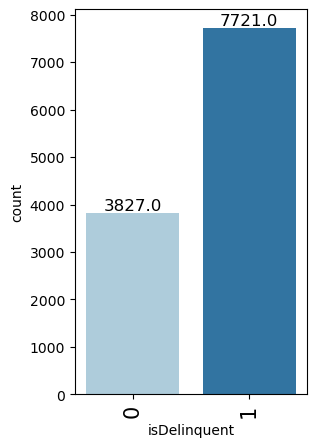

In [19]:
# Univariate analysis: distribution of the target variable (class balance check)
labeled_barplot(loan, "isDelinquent")

**Observations:**

- **7,721 loans (about 66.9%) are delinquent** and 3,827 (about 33.1%) are not.
- The target is imbalanced, roughly 2:1, which is why oversampling and undersampling are tried later.
- Accuracy alone would be misleading here, so recall, precision and F1 are also tracked.

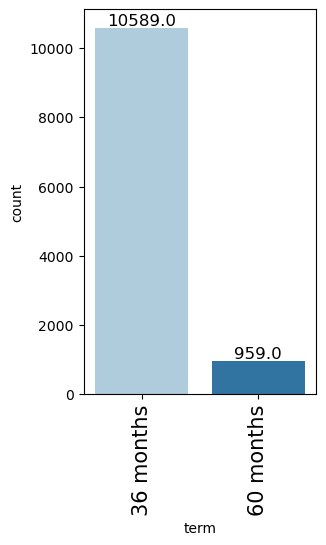

In [20]:
# Univariate analysis: loan term (36 / 60 months)
labeled_barplot(loan, "term")

**Observations:**

- About **91.7% of loans (10,589) are 36-month** loans, and only about 8.3% (959) are 60-month loans.
- The 60-month group is small, so conclusions about it are less reliable.

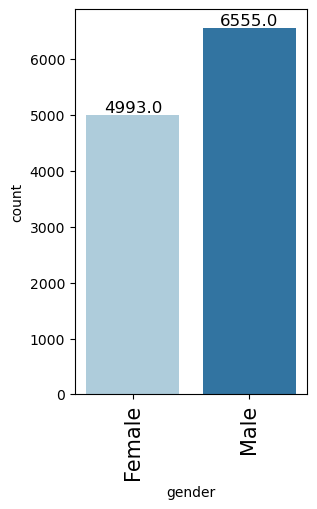

In [21]:
# Univariate analysis: gender of the borrower
labeled_barplot(loan, "gender")

**Observations:**

- Male borrowers make up about 56.8% (6,555) of the data and Female borrowers about 43.2% (4,993).
- The gender split is fairly balanced.

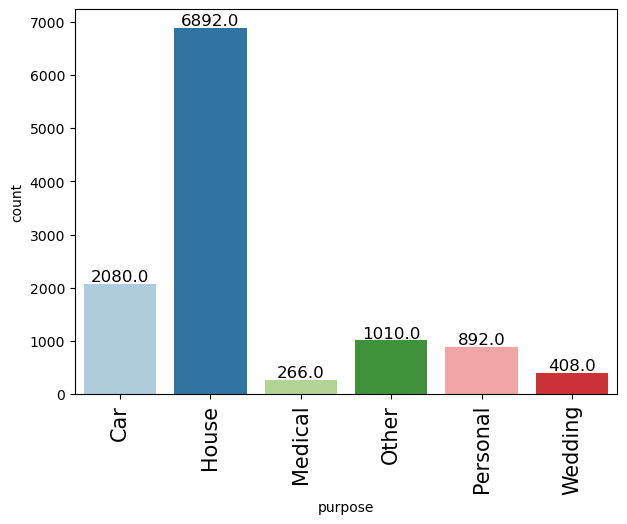

In [22]:
# Univariate analysis: purpose of the loan
labeled_barplot(loan, "purpose")

**Observations:**

- **House loans dominate with about 59.7%** (6,892), followed by Car at about 18.0% (2,080).
- Other (about 8.7%), Personal (about 7.7%), Wedding (about 3.5%) and Medical (about 2.3%) are much smaller groups.
- Medical and Wedding have few records, so their estimates will be less stable.

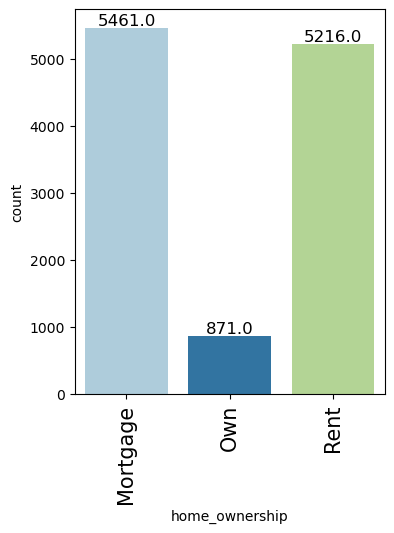

In [23]:
# Univariate analysis: home ownership status
labeled_barplot(loan, "home_ownership")

**Observations:**

- Mortgage (about 47.3%) and Rent (about 45.2%) are almost equally common.
- Only about 7.5% (871) of borrowers own their home outright.

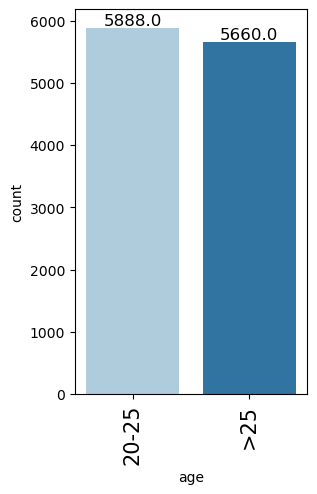

In [24]:
# Univariate analysis: age group of the borrower
labeled_barplot(loan, "age")

**Observations:**

- The two age groups are almost evenly split: 20-25 has 5,888 borrowers (about 51.0%) and >25 has 5,660 (about 49.0%).
- Age is nearly balanced, so neither group dominates the model.

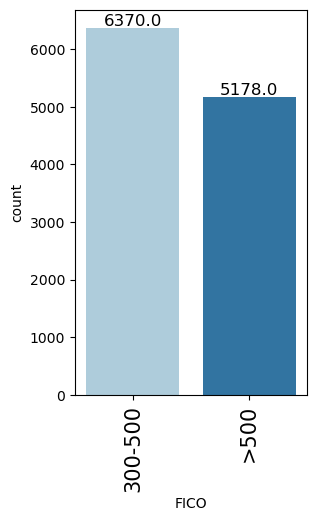

In [25]:
# Univariate analysis: FICO (credit score) band
labeled_barplot(loan, "FICO")

**Observations:**

- More borrowers fall in the low FICO band **300-500 (about 55.2%, 6,370)** than in the >500 band (about 44.8%, 5,178).
- More than half of the borrowers have a weak credit score.

In [26]:
# --- Helper function: stacked bar plot to compare a predictor with the target ---
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()  # Number of categories (used for figure width)
    sorter = data[target].value_counts().index[-1]  # Least frequent class, used to sort the bars

    # Table of raw counts (with row/column totals)
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)  # Separator line

    # Table of row-wise proportions, which is what the chart displays
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left",
        frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # Move the legend outside the plot
    plt.show()

**Observations:**

- The `stacked_barplot` helper is defined, which prints a count table and plots the row-wise proportions of the target (or another variable) for each category.
- It is used for all the bivariate analysis below.

isDelinquent     0     1    All
term                           
All           3827  7721  11548
36 months     3168  7421  10589
60 months      659   300    959
------------------------------------------------------------------------------------------------------------------------


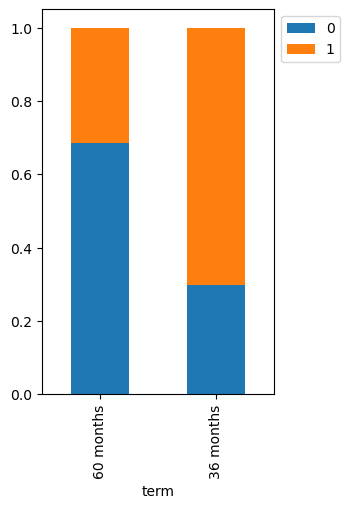

In [27]:
# Bivariate analysis: term vs delinquency
stacked_barplot(loan, "term", "isDelinquent")

**Observations:**

- **36-month loans:** 7,421 of 10,589 are delinquent (about 70.1%).
- **60-month loans:** only 300 of 959 are delinquent (about 31.3%).
- Longer-term loans show a much lower delinquency rate in this data, which is a strong and somewhat counter-intuitive pattern. It may reflect how longer-term loans are approved.

isDelinquent     0     1    All
gender                         
All           3827  7721  11548
Male          1977  4578   6555
Female        1850  3143   4993
------------------------------------------------------------------------------------------------------------------------


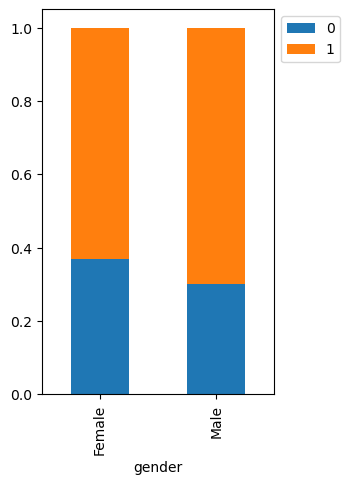

In [28]:
# Bivariate analysis: gender vs delinquency
stacked_barplot(loan, "gender", "isDelinquent")

**Observations:**

- **Male:** about 69.8% delinquent (4,578 of 6,555). **Female:** about 62.9% delinquent (3,143 of 4,993).
- Male borrowers are delinquent about 7 percentage points more often than Female borrowers.

isDelinquent     0     1    All
purpose                        
All           3827  7721  11548
House         2272  4620   6892
Car            678  1402   2080
Other          357   653   1010
Personal       274   618    892
Wedding        139   269    408
Medical        107   159    266
------------------------------------------------------------------------------------------------------------------------


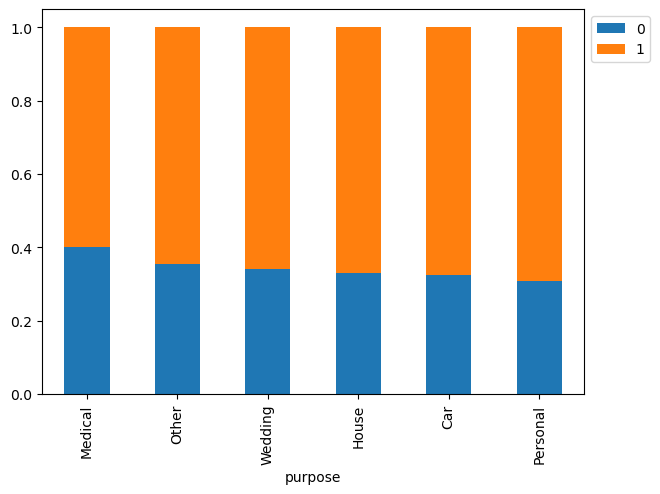

In [29]:
# Bivariate analysis: loan purpose vs delinquency
stacked_barplot(loan, "purpose", "isDelinquent")

**Observations:**

- Delinquency is highest for **Personal loans (about 69.3%)**, followed by Car (67.4%), House (67.0%), Wedding (65.9%) and Other (64.7%).
- **Medical loans have the lowest rate (about 59.8%)**.
- Apart from Medical, the purposes differ by only a few percentage points, so purpose looks like a weak predictor.

isDelinquent       0     1    All
home_ownership                   
All             3827  7721  11548
Mortgage        1831  3630   5461
Rent            1737  3479   5216
Own              259   612    871
------------------------------------------------------------------------------------------------------------------------


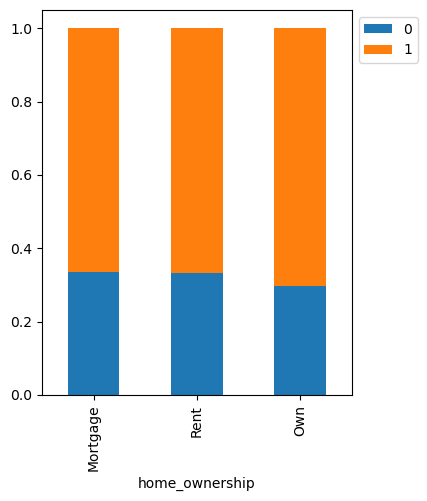

In [30]:
# Bivariate analysis: home ownership vs delinquency
stacked_barplot(loan, "home_ownership", "isDelinquent")

**Observations:**

- **Own:** about 70.3% delinquent. **Rent:** about 66.7%. **Mortgage:** about 66.5%.
- Renters and mortgage holders are almost identical, and outright owners are slightly higher. The differences are small.

isDelinquent     0     1    All
age                            
All           3827  7721  11548
>25           1969  3691   5660
20-25         1858  4030   5888
------------------------------------------------------------------------------------------------------------------------


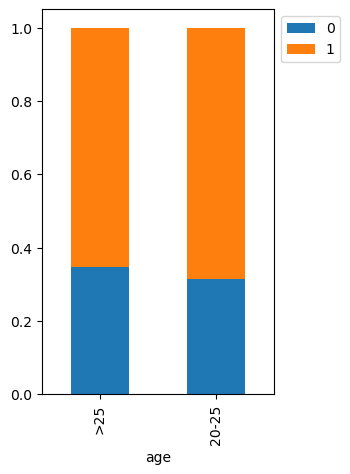

In [31]:
# Bivariate analysis: age group vs delinquency
stacked_barplot(loan, "age", "isDelinquent")

**Observations:**

- **20-25 age group:** about 68.4% delinquent. **>25 age group:** about 65.2% delinquent.
- Younger borrowers are slightly more likely to be delinquent, but the gap is only about 3 percentage points.

isDelinquent     0     1    All
FICO                           
All           3827  7721  11548
>500          2886  2292   5178
300-500        941  5429   6370
------------------------------------------------------------------------------------------------------------------------


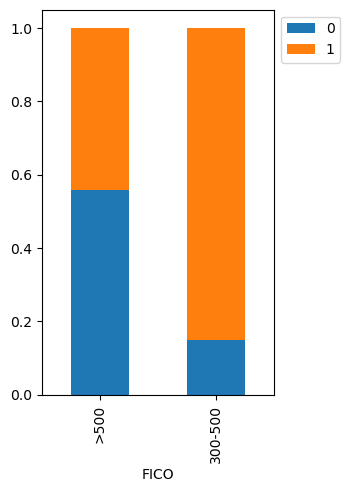

In [32]:
# Bivariate analysis: FICO band vs delinquency
stacked_barplot(loan, "FICO", "isDelinquent")

**Observations:**

- **FICO 300-500:** about 85.2% delinquent (5,429 of 6,370). **FICO >500:** about 44.3% delinquent (2,292 of 5,178).
- FICO is the **strongest predictor** so far: low-score borrowers are almost twice as likely to be delinquent.
- This matches business intuition, since a lower credit score means higher credit risk.

FICO            300-500  >500    All
home_ownership                      
All                6370  5178  11548
Mortgage           2857  2604   5461
Rent               3033  2183   5216
Own                 480   391    871
------------------------------------------------------------------------------------------------------------------------


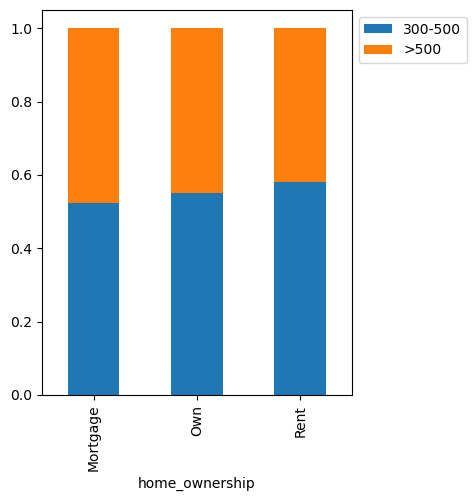

In [33]:
# Relationship between predictors: home ownership vs FICO
stacked_barplot(loan, "home_ownership", "FICO")

**Observations:**

- The share of >500 FICO borrowers is about 47.7% for Mortgage, 44.9% for Own and 41.9% for Rent.
- Renters have a slightly weaker credit profile than mortgage holders, but the difference is modest.

FICO   300-500  >500    All
age                        
All       6370  5178  11548
>25       2443  3217   5660
20-25     3927  1961   5888
------------------------------------------------------------------------------------------------------------------------


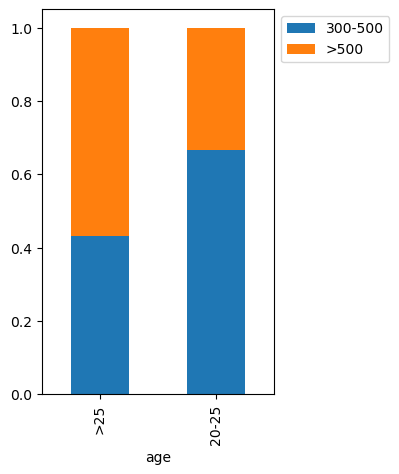

In [34]:
# Relationship between predictors: age group vs FICO
stacked_barplot(loan, "age", "FICO")

**Observations:**

- **>25 age group:** about 56.8% have FICO >500. **20-25 age group:** only about 33.3% have FICO >500.
- Older borrowers have clearly better credit scores, so age and FICO are related.
- This overlap matters later when interpreting the model coefficients.

FICO    300-500  >500    All
gender                      
All        6370  5178  11548
Male       3705  2850   6555
Female     2665  2328   4993
------------------------------------------------------------------------------------------------------------------------


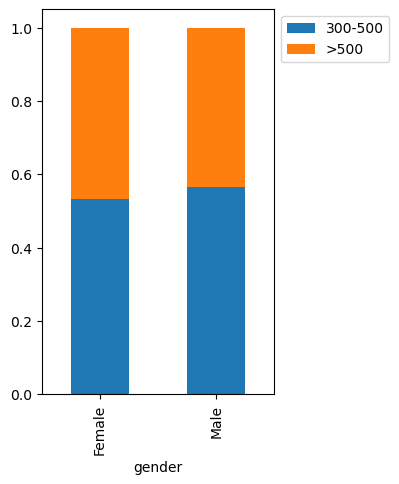

In [35]:
# Relationship between predictors: gender vs FICO
stacked_barplot(loan, "gender", "FICO")

**Observations:**

- About 43.5% of Male borrowers and about 46.6% of Female borrowers have FICO >500.
- Credit scores are fairly similar across genders, with Females slightly better.

In [36]:
# ---------------------------------------------------------------
# 5. CHI-SQUARE TESTS OF INDEPENDENCE (FICO vs other variables)
# ---------------------------------------------------------------

# Test 1: FICO vs home ownership
crosstab = pd.crosstab(
    loan["FICO"], loan["home_ownership"]
)  # Contingency table of the two categorical variables

Ho = "FICO score has no effect on home ownership"  # Null hypothesis
Ha = "FICO score has an effect on home ownership"  # Alternative hypothesis

# Returns: chi-square statistic, p-value, degrees of freedom, expected frequencies
chi, p_value, dof, expected = stats.chi2_contingency(crosstab)

# Decision rule at 5% significance level
if p_value < 0.05:  # Reject the null hypothesis
    print(f"{Ha} as the p_value ({p_value.round(3)}) < 0.05")
else:  # Fail to reject the null hypothesis
    print(f"{Ho} as the p_value ({p_value.round(3)}) > 0.05")

FICO score has an effect on home ownership as the p_value (0.0) < 0.05


**Observations:**

- The p-value is about 0.0 (below 0.05), so the null hypothesis is rejected: **FICO and home ownership are statistically associated**.
- From the earlier chart, the effect is modest: Mortgage holders have the best scores and Renters the weakest.
- With a large sample, even small differences can show up as statistically significant.

In [37]:
# Test 2: FICO vs gender
crosstab = pd.crosstab(
    loan["FICO"], loan["gender"]
)  # Contingency table

Ho = "FICO score has no effect on gender"  # Null hypothesis
Ha = "FICO score has an effect on gender"  # Alternative hypothesis

chi, p_value, dof, expected = stats.chi2_contingency(crosstab)

if p_value < 0.05:  # Reject the null hypothesis
    print(f"{Ha} as the p_value ({p_value.round(3)}) < 0.05")
else:  # Fail to reject the null hypothesis
    print(f"{Ho} as the p_value ({p_value.round(3)}) > 0.05")

FICO score has an effect on gender as the p_value (0.001) < 0.05


**Observations:**

- The p-value is about 0.001 (below 0.05), so **FICO and gender are statistically associated**.
- The actual difference is small (43.5% vs 46.6% with FICO >500), so the practical impact is limited.

In [38]:
# Test 3: FICO vs age
crosstab = pd.crosstab(
    loan["FICO"], loan["age"]
)  # Contingency table

Ho = "FICO score has no effect on age"  # Null hypothesis
Ha = "FICO score has an effect on age"  # Alternative hypothesis

chi, p_value, dof, expected = stats.chi2_contingency(crosstab)

if p_value < 0.05:  # Reject the null hypothesis
    print(f"{Ha} as the p_value ({p_value.round(3)}) < 0.05")
else:  # Fail to reject the null hypothesis
    print(f"{Ho} as the p_value ({p_value.round(3)}) > 0.05")

FICO score has an effect on age as the p_value (0.0) < 0.05


**Observations:**

- The p-value is about 0.0 (below 0.05), so **FICO and age are strongly associated**.
- This is the largest gap of the three (56.8% vs 33.3% with FICO >500), so it is both statistically and practically significant.

In [39]:
# ---------------------------------------------------------------
# 6. DATA PREPARATION FOR MODELLING
# ---------------------------------------------------------------

# Separate independent variables (x) from the target variable (y)
x = loan.drop(["isDelinquent"], axis=1)
y = loan["isDelinquent"]

**Observations:**

- The data is split into predictors (`x`) and the target (`y` = `isDelinquent`).

In [40]:
# One-hot encode the categorical columns into 0/1 dummy variables.
# drop_first=True removes one category per column to avoid multicollinearity.
x = pd.get_dummies(x, drop_first=True)
x.head()

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
0,False,False,True,False,False,False,False,False,False,True,False
1,False,False,True,False,False,False,False,False,True,False,True
2,False,False,True,False,False,False,False,False,True,True,False
3,False,False,False,False,False,False,False,False,False,True,False
4,False,False,True,False,False,False,False,False,True,True,False


**Observations:**

- Categorical columns are one-hot encoded, giving **11 predictor columns**.
- `drop_first=True` removes one reference category per variable. The reference levels are term = 36 months, gender = Female, purpose = Car, home ownership = Mortgage, age = 20-25 and FICO = 300-500.
- This avoids multicollinearity and sets the baseline for interpreting the coefficients.

In [41]:
# Split the data into Train (60%), Validation (20%) and Test (20%)

# Step 1: hold out 20% of the data as the test set
# stratify=y keeps the same delinquent / non-delinquent ratio in every split
X_temp, X_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.2, random_state=1, stratify=y
)

# Step 2: split the remaining 80% into train (60% overall) and validation (20% overall)
# 0.25 * 80% = 20% of the original data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print(X_train.shape, X_val.shape, X_test.shape)

(6928, 11) (2310, 11) (2310, 11)


**Observations:**

- The data is split into **train 6,928 rows (60%), validation 2,310 (20%) and test 2,310 (20%)**.
- Stratified splitting keeps the delinquent / non-delinquent ratio the same in every set.
- The validation set is for choosing between models, and the test set is kept for the final unbiased check.

In [42]:
# Print the number of rows in each dataset
print("Number of rows in train data =", X_train.shape[0])
print("Number of rows in validation data =", X_val.shape[0])
print("Number of rows in test data =", X_test.shape[0])

Number of rows in train data = 6928
Number of rows in validation data = 2310
Number of rows in test data = 2310


**Observations:**

- The row counts confirm the split: train 6,928, validation 2,310 and test 2,310 (total 11,548).

In [43]:
# ---------------------------------------------------------------
# 7. MODEL EVALUATION HELPER FUNCTIONS
# ---------------------------------------------------------------

def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # Predict class labels using the given model
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # Overall proportion of correct predictions
    recall = recall_score(target, pred)  # Of all actual delinquents, how many were caught
    precision = precision_score(target, pred)  # Of all predicted delinquents, how many were correct
    f1 = f1_score(target, pred)  # Harmonic mean of precision and recall

    # Collect all metrics in a single-row DataFrame
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1": f1,
        },
        index=[0],
    )

    return df_perf

**Observations:**

- The `model_performance_classification_sklearn` helper returns Accuracy, Recall, Precision and F1 in one table.
- It lets all models be compared in the same format.

In [44]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)  # Predicted classes
    cm = confusion_matrix(target, y_pred)  # 2x2 matrix of actual vs predicted

    # Build the text shown in each cell: count and percentage of the total
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    # Draw the confusion matrix as a heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

**Observations:**

- The `confusion_matrix_sklearn` helper plots a confusion matrix showing both counts and percentages.
- In these matrices, rows are the true class and columns are the predicted class (1 = delinquent).

In [45]:
# ---------------------------------------------------------------
# 8. MODEL 1: BASE LOGISTIC REGRESSION
# ---------------------------------------------------------------

# Build and train the logistic regression model on the original training data
lr = LogisticRegression(random_state=1)
lr.fit(X_train, y_train)

LogisticRegression(random_state=1)

**Observations:**

- A base logistic regression is trained on the original (imbalanced) training data.

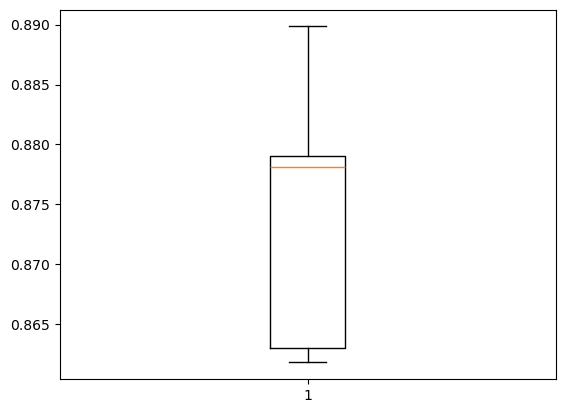

In [46]:
# Cross-validation on the training data to check model stability
scoring = "recall"  # Recall is the key metric: we want to catch as many delinquent loans as possible
kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # 5 folds; stratified so each fold keeps the same class ratio
cv_result_bfr = cross_val_score(
    estimator=lr, X=X_train, y=y_train, scoring=scoring, cv=kfold
)
plt.boxplot(cv_result_bfr)  # Spread of recall scores across the 5 folds
plt.show()

**Observations:**

- Five-fold cross-validated recall for the base model lies between about **0.86 and 0.89**, with a median near 0.88.
- The narrow spread means the model is stable across folds.

In [47]:
# Performance of the base model on the training data
log_reg_model_train_perf = model_performance_classification_sklearn(
    lr, X_train, y_train
)
print("Training performance:")
log_reg_model_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.782621,0.872409,0.815375,0.842929


**Observations:**

- Training: Accuracy about 0.783, Recall about 0.872, Precision about 0.815 and F1 about 0.843.
- The model finds most delinquent loans, since recall is high. This is partly because the majority class is delinquent.

In [48]:
# Performance of the base model on the validation data
log_reg_model_val_perf = model_performance_classification_sklearn(lr, X_val, y_val)
print("Validation performance:")
log_reg_model_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.797403,0.891909,0.820727,0.854839


**Observations:**

- Validation: Accuracy about 0.797, Recall about 0.892, Precision about 0.821 and F1 about 0.855.
- Validation scores are slightly higher than training scores, so there is **no overfitting**.
- This is the best recall of all four models.

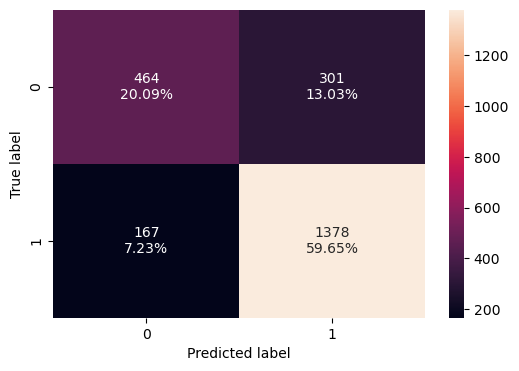

In [49]:
# Confusion matrix of the base model on the validation data
confusion_matrix_sklearn(lr, X_val, y_val)

**Observations:**

- On validation data: **1,378 true positives, 464 true negatives, 301 false positives and 167 false negatives**.
- Only about 7.2% of all loans are missed delinquents (false negatives), but about 13.0% are non-delinquent loans wrongly flagged (false positives).
- The model leans towards predicting delinquency, which is expected because delinquency is the majority class.

In [50]:
# ---------------------------------------------------------------
# 9. MODEL 2: LOGISTIC REGRESSION WITH OVERSAMPLING (SMOTE)
# ---------------------------------------------------------------

# Class counts before balancing
print("Before UpSampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before UpSampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

# Convert Boolean columns to numeric values (SMOTE needs numeric input)
X_train = X_train.astype(float)

# SMOTE creates synthetic samples of the minority class
sm = SMOTE(
    sampling_strategy=1,  # Make minority class equal to the majority class (1:1)
    k_neighbors=5,  # Number of nearest neighbours used to create synthetic samples
    random_state=1
)

# Oversampling is applied ONLY on the training data (never on validation/test data)
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)

# Class counts after balancing
print("After UpSampling, counts of label 'Yes': {}".format(sum(y_train_over == 1)))
print("After UpSampling, counts of label 'No': {} \n".format(sum(y_train_over == 0)))

print("After UpSampling, the shape of train_X: {}".format(X_train_over.shape))
print("After UpSampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before UpSampling, counts of label 'Yes': 4632
Before UpSampling, counts of label 'No': 2296 

After UpSampling, counts of label 'Yes': 4632
After UpSampling, counts of label 'No': 4632 

After UpSampling, the shape of train_X: (9264, 11)
After UpSampling, the shape of train_y: (9264,) 



**Observations:**

- Before balancing, the training set has 4,632 delinquent and 2,296 non-delinquent loans.
- SMOTE creates synthetic minority-class rows, so both classes now have **4,632** rows and the training set grows to 9,264 rows.
- Oversampling is applied only to the training data, so the validation and test sets still reflect real-world proportions.

In [51]:
# Train logistic regression on the oversampled (balanced) training data
log_reg_over = LogisticRegression(random_state=1)
log_reg_over.fit(X_train_over, y_train_over)

LogisticRegression(random_state=1)

**Observations:**

- A logistic regression is trained on the balanced (SMOTE) training data.

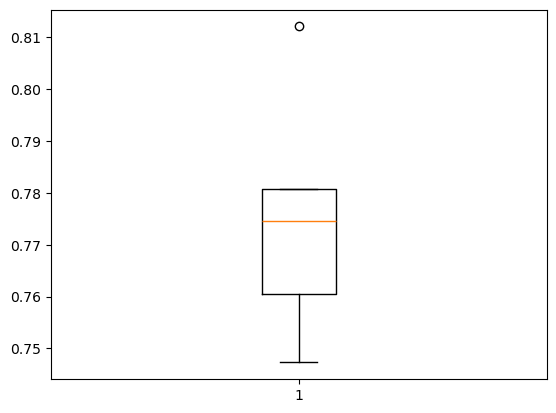

In [52]:
# Cross-validation (recall) for the oversampled model
scoring = "recall"
kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)
cv_result_over = cross_val_score(
    estimator=log_reg_over, X=X_train_over, y=y_train_over, scoring=scoring, cv=kfold
)
plt.boxplot(cv_result_over)
plt.show()

**Observations:**

- Cross-validated recall is lower than for the base model, with a median near **0.775** (range about 0.75 to 0.78) and one high outlier near 0.81.
- Recall drops because the model no longer simply favours the majority class.

In [53]:
# Oversampled model: performance on the (balanced) training data
log_reg_over_train_perf = model_performance_classification_sklearn(
    log_reg_over, X_train_over, y_train_over
)
print("Training performance:")
log_reg_over_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.790803,0.771805,0.802289,0.786752


**Observations:**

- Training (balanced data): Accuracy about 0.791, Recall about 0.772, Precision about 0.802 and F1 about 0.787.
- Recall and precision are well balanced, as expected on balanced data.

In [54]:
# Oversampled model: performance on the original validation data
log_reg_over_val_perf = model_performance_classification_sklearn(
    log_reg_over, X_val, y_val
)
print("validation performance:")
log_reg_over_val_perf

validation performance:


,Accuracy,Recall,Precision,F1
0,0.794372,0.792233,0.888244,0.837496


**Observations:**

- Validation: Accuracy about 0.794, Recall about 0.792, Precision about 0.888 and F1 about 0.837.
- Precision rises noticeably (0.821 to 0.888) but recall falls (0.892 to 0.792) compared with the base model.
- Training and validation scores are close, so the model generalises well.

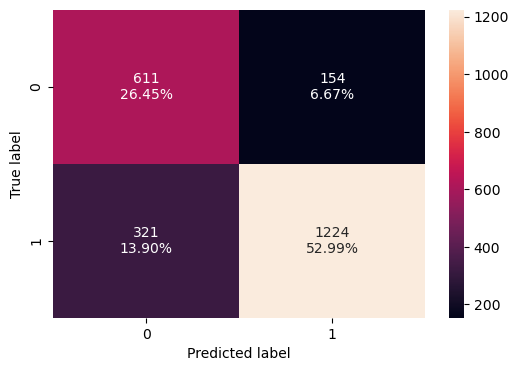

In [55]:
# Oversampled model: confusion matrix on the validation data
confusion_matrix_sklearn(log_reg_over, X_val, y_val)

**Observations:**

- On validation data: **1,224 true positives, 611 true negatives, 154 false positives and 321 false negatives**.
- False positives are cut by half (301 to 154), but false negatives almost double (167 to 321).
- This model is more careful about flagging delinquency, but it misses more delinquent loans.

In [56]:
# ---------------------------------------------------------------
# 10. MODEL 3: REGULARISED LOGISTIC REGRESSION (on oversampled data)
# ---------------------------------------------------------------

# 'saga' solver supports regularisation
lr_estimator = LogisticRegression(random_state=1, solver="saga")

# Grid of values for C (inverse of regularisation strength): 0.1, 0.2, ..., 1.0
# Smaller C = stronger regularisation
parameters = {"C": np.arange(0.1, 1.1, 0.1)}

# Search for the C value that gives the best recall
grid_obj = GridSearchCV(lr_estimator, parameters, scoring="recall")
grid_obj = grid_obj.fit(X_train_over, y_train_over)

# Select the best model found by the grid search
lr_estimator = grid_obj.best_estimator_

# Fit the best model on the full oversampled training data
lr_estimator.fit(X_train_over, y_train_over)

LogisticRegression(C=np.float64(0.6), random_state=1, solver='saga')

**Observations:**

- Grid search over the regularisation strength `C` (0.1 to 1.0) picks **C = 0.6** as the best value for recall.
- The final model is refit on the oversampled training data.

In [57]:
# Regularised model: performance on the training data
log_reg_reg_train_perf = model_performance_classification_sklearn(
    lr_estimator, X_train_over, y_train_over
)
print("Training performance:")
log_reg_reg_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.790911,0.771805,0.802469,0.786838


**Observations:**

- Training: Accuracy about 0.791, Recall about 0.772, Precision about 0.802 and F1 about 0.787.
- These values are almost identical to the un-regularised oversampled model.

In [58]:
# Regularised model: performance on the validation data
log_reg_reg_val_perf = model_performance_classification_sklearn(
    lr_estimator, X_val, y_val
)
print("Validation performance:")
log_reg_reg_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.794372,0.792233,0.888244,0.837496


**Observations:**

- Validation: Accuracy about 0.794, Recall about 0.792, Precision about 0.888 and F1 about 0.837.
- Scores are **exactly the same** as the un-regularised oversampled model, so regularisation adds no benefit here.
- This is expected, since there are only 11 predictors and plenty of data, which leaves little room to overfit.

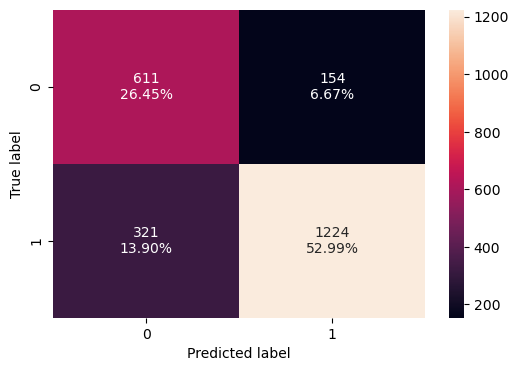

In [59]:
# Regularised model: confusion matrix on the validation data
confusion_matrix_sklearn(lr_estimator, X_val, y_val)

**Observations:**

- The confusion matrix matches the oversampled model exactly (1,224 TP, 611 TN, 154 FP and 321 FN).

In [60]:
# ---------------------------------------------------------------
# 11. MODEL 4: LOGISTIC REGRESSION WITH UNDERSAMPLING
# ---------------------------------------------------------------

# Randomly remove majority-class rows so both classes have equal counts
# (applied only on the training data)
rus = RandomUnderSampler(random_state=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

**Observations:**

- Random undersampling is applied to the training data. Rows from the majority class (delinquent) are removed until both classes are equal.

In [61]:
# Compare class counts before and after undersampling
print("Before Under Sampling, counts of label 'Yes': {}".format(sum(y_train == 1)))
print("Before Under Sampling, counts of label 'No': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, counts of label 'Yes': {}".format(sum(y_train_un == 1)))
print("After Under Sampling, counts of label 'No': {} \n".format(sum(y_train_un == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))

Before Under Sampling, counts of label 'Yes': 4632
Before Under Sampling, counts of label 'No': 2296 

After Under Sampling, counts of label 'Yes': 2296
After Under Sampling, counts of label 'No': 2296 

After Under Sampling, the shape of train_X: (4592, 11)
After Under Sampling, the shape of train_y: (4592,) 



**Observations:**

- Both classes now have **2,296 rows each**, so the training set shrinks from 6,928 to 4,592 rows.
- Balancing is achieved, but about 2,336 delinquent records (about 50% of the training data) are discarded, so useful information is lost.

In [62]:
# Train logistic regression on the undersampled (balanced) training data
log_reg_under = LogisticRegression(random_state=1)
log_reg_under.fit(X_train_un, y_train_un)

LogisticRegression(random_state=1)

**Observations:**

- A logistic regression is trained on the undersampled (balanced) training data.

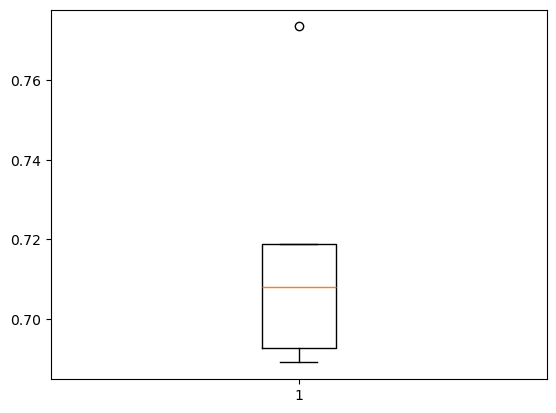

In [63]:
# Cross-validation (recall) for the undersampled model
scoring = "recall"
kfold = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)
cv_result_under = cross_val_score(
    estimator=log_reg_under, X=X_train_un, y=y_train_un, scoring=scoring, cv=kfold
)
plt.boxplot(cv_result_under)
plt.show()

**Observations:**

- Cross-validated recall is the lowest of the three, with a median near **0.71** (range about 0.69 to 0.72) and one outlier near 0.77.
- The smaller training set and the lost records reduce the model's ability to catch delinquent loans.

In [64]:
# Undersampled model: performance on the training data
log_reg_under_train_perf = model_performance_classification_sklearn(
    log_reg_under, X_train_un, y_train_un
)
print("Training performance:")
log_reg_under_train_perf

Training performance:


,Accuracy,Recall,Precision,F1
0,0.768075,0.708624,0.804251,0.753415


**Observations:**

- Training: Accuracy about 0.768, Recall about 0.709, Precision about 0.804 and F1 about 0.753.
- These are the lowest training scores of all the models.

In [65]:
# Undersampled model: performance on the validation data
log_reg_under_val_perf = model_performance_classification_sklearn(
    log_reg_under, X_val, y_val
)
print("Validation performance:")
log_reg_under_val_perf

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.769264,0.739806,0.897174,0.810926


**Observations:**

- Validation: Accuracy about 0.769, Recall about 0.740, Precision about 0.897 and F1 about 0.811.
- This model has the **highest precision** (0.897), meaning that when it predicts delinquency it is right about 90% of the time.
- The price is the lowest recall (0.740) and lowest accuracy of the four models.

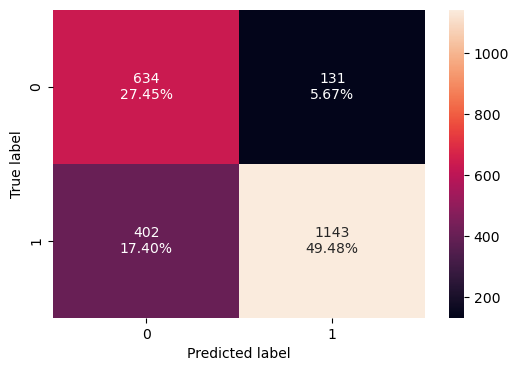

In [66]:
# Undersampled model: confusion matrix on the validation data
confusion_matrix_sklearn(log_reg_under, X_val, y_val)

**Observations:**

- On validation data: **1,143 true positives, 634 true negatives, 131 false positives and 402 false negatives**.
- It has the fewest false positives (131) but the most false negatives (402).
- About 17.4% of all loans are delinquent loans the model fails to catch.

In [67]:
# ---------------------------------------------------------------
# 12. MODEL COMPARISON
# ---------------------------------------------------------------

# Combine the training metrics of all four models side by side
models_train_comp_df = pd.concat(
    [
        log_reg_model_train_perf.T,
        log_reg_over_train_perf.T,
        log_reg_reg_train_perf.T,
        log_reg_under_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.782621,0.790803,0.790911,0.768075
Recall,0.872409,0.771805,0.771805,0.708624
Precision,0.815375,0.802289,0.802469,0.804251
F1,0.842929,0.786752,0.786838,0.753415


**Observations:**

- **Training comparison:** the base model has the highest recall (0.872) and F1 (0.843), while the undersampled model scores lowest on every metric except precision, where all models are similar (about 0.80 to 0.82).
- The oversampled and regularised models are practically identical (accuracy 0.791, recall 0.772).

In [68]:
# Combine the validation metrics of all four models side by side
# (note: the variable name is reused from the previous cell, but it now holds validation results)
models_train_comp_df = pd.concat(
    [
        log_reg_model_val_perf.T,
        log_reg_over_val_perf.T,
        log_reg_reg_val_perf.T,
        log_reg_under_val_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Validation performance comparison:")
models_train_comp_df

Validation performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.797403,0.794372,0.794372,0.769264
Recall,0.891909,0.792233,0.792233,0.739806
Precision,0.820727,0.888244,0.888244,0.897174
F1,0.854839,0.837496,0.837496,0.810926


**Observations:**

- **Validation comparison:**
- Base model: best recall (0.892), best accuracy (0.797) and best F1 (0.855).
- Oversampled / regularised: recall 0.792, precision 0.888 and F1 0.837.
- Undersampled: best precision (0.897) but lowest recall (0.740) and F1 (0.811).
- If the business goal is to catch as many delinquent loans as possible (recall), the **base model performs best** on validation. If the goal is to avoid false alarms (precision), the undersampled model performs best.
- Resampling did not improve recall in this case. It only traded recall for precision.

In [69]:
# ---------------------------------------------------------------
# 13. FINAL MODEL EVALUATION ON TEST DATA
# ---------------------------------------------------------------

# Evaluate the chosen model (undersampled logistic regression) on unseen test data
log_reg_model_test_perf = model_performance_classification_sklearn(
    log_reg_under, X_test, y_test
)
print("Test performance:")
log_reg_model_test_perf

Test performance:


,Accuracy,Recall,Precision,F1
0,0.765368,0.733808,0.896361,0.80698


**Observations:**

- The undersampled model on the test set gives Accuracy about 0.765, Recall about 0.734, Precision about 0.896 and F1 about 0.807.
- These are very close to its validation results (0.769 / 0.740 / 0.897 / 0.811), so the model is **stable and generalises well** to unseen data.
- However, the validation comparison above favoured the base model on recall, so the reason for choosing the undersampled model here should be stated (for example, a preference for precision).

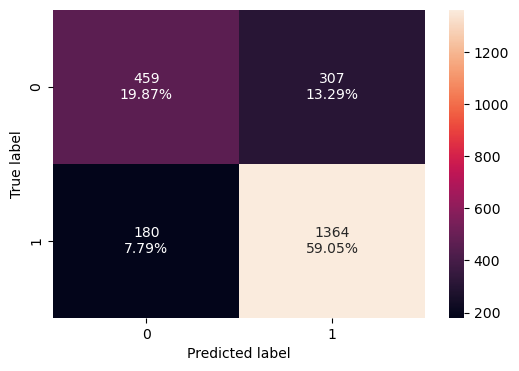

In [70]:
# Confusion matrix on the test data
# NOTE: this uses the base model 'lr', whereas the test metrics above use 'log_reg_under'
confusion_matrix_sklearn(lr, X_test, y_test)

**Observations:**

- This confusion matrix is for the **base model (`lr`)**, not the undersampled model whose test metrics were shown above.
- On test data: 1,364 true positives, 459 true negatives, 307 false positives and 180 false negatives.
- Its pattern matches the validation result for the same model (high recall, more false positives), which again shows consistent behaviour on unseen data.
- To report one consistent final model, the same model should be used in both cells.

In [71]:
# ---------------------------------------------------------------
# 14. MODEL INTERPRETATION
# ---------------------------------------------------------------

# Coefficients of the base logistic regression model (plus the intercept)
# A positive coefficient raises the probability of delinquency; a negative one lowers it
coef_df = pd.DataFrame(
    np.append(lr.coef_, lr.intercept_),
    index=X_train.columns.tolist() + ["Intercept"],
    columns=["Coefficients"],
)
coef_df.T  # Transpose for a wide, easy-to-read layout

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500,Intercept
Coefficients,-2.033788,0.790446,0.086187,0.409481,-0.050275,0.171595,0.044048,0.103589,-0.089995,0.563389,-1.981912,1.165601


**Observations:**

- Coefficients are from the base logistic regression. Positive values raise the log-odds of delinquency and negative values lower them, compared with the reference category.
- **Largest negative effects:** `term_60 months` (-2.03) and `FICO_>500` (-1.98).
- **Largest positive effects:** `gender_Male` (+0.79), `age_>25` (+0.56) and `purpose_Medical` (+0.41).
- The remaining variables (`purpose_House`, `purpose_Other`, `purpose_Personal`, `purpose_Wedding`, `home_ownership_Own`, `home_ownership_Rent`) have small coefficients (below about 0.2 in absolute value), so they have little influence.

In [72]:
# Convert coefficients to odds ratios: odds = exp(coefficient)
# Odds > 1 -> increases likelihood of delinquency, odds < 1 -> decreases it
odds = np.exp(lr.coef_[0])
pd.set_option(
    "display.max_columns", None
)  # Show all columns without truncation
pd.DataFrame(
    odds, X_train.columns, columns=["odds"]
).T  # Odds ratio for each feature

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
odds,0.130839,2.204379,1.09001,1.506036,0.950968,1.187197,1.045032,1.109145,0.913936,1.756616,0.137805


**Observations:**

- Odds ratios (exp of the coefficient) compared with the reference group:
- `term_60 months` = 0.13 and `FICO_>500` = 0.14, so these cut the odds of delinquency by about 86 to 87%.
- `gender_Male` = 2.20, so Male borrowers have about twice the odds of Female borrowers, holding other factors constant.
- `age_>25` = 1.76 and `purpose_Medical` = 1.51 also increase the odds.
- Odds close to 1 (Other 0.95, Wedding 1.05, House 1.09, Own 1.11, Rent 0.91, Personal 1.19) show weak effects.

In [73]:
# Percentage change in odds for a one-unit increase in each feature
# formula: (exp(coefficient) - 1) * 100
perc_change_odds = (np.exp(lr.coef_[0]) - 1) * 100
pd.set_option(
    "display.max_columns", None
)  # Show all columns without truncation
pd.DataFrame(
    perc_change_odds, X_train.columns, columns=["change_odds%"]
).T  # % change in odds for each feature

,term_60 months,gender_Male,purpose_House,purpose_Medical,purpose_Other,purpose_Personal,purpose_Wedding,home_ownership_Own,home_ownership_Rent,age_>25,FICO_>500
change_odds%,-86.916105,120.437917,9.001019,50.603603,-4.903246,18.719705,4.503241,10.914457,-8.60642,75.661593,-86.219456


**Observations:**

- **Change in odds:** 60-month term -86.9% and FICO >500 -86.2%. Male +120.4%, age >25 +75.7% and Medical purpose +50.6%.
- The values are for a switch from the reference category to the stated category (these are dummy variables, not one-unit increases).
- **Caution on age:** in the earlier bivariate chart, the >25 group was *less* delinquent (65.2% vs 68.4%), but here its coefficient is *positive*. This happens because older borrowers also tend to have higher FICO scores. Once FICO is held constant, older borrowers carry higher odds of delinquency.
- **Key takeaways:** credit score (FICO) and loan term are the strongest protective factors, while being Male and age >25 (after controlling for FICO) are associated with higher delinquency risk.